# Лабораторная работа 3: генерация текстового описания к изображению (BLIP)

**Задача.** На вход подаётся изображение (.png / .bmp / .jpg), на выходе получается его описание на естественном языке (английском).

**Подход.** Готовая модель BLIP ([Li et al., 2022](https://arxiv.org/abs/2201.12086)), версия `Salesforce/blip-image-captioning-base`, дообученная на датасете VizWiz:
- **кодировщик изображения** ViT-B/16 делит картинку 384×384 на кусочки 16×16 и превращает её в набор признаков;
- **текстовый декодер** (трансформер) пишет описание слово за словом, на каждом шаге «заглядывая» в признаки картинки.

BLIP выбрана вместо предложенной в задании архитектуры ([Das & Saha, 2021](https://arxiv.org/abs/2112.04928): автокодировщики, LSTM и GAN), потому что это современная модель, созданная именно для описания изображений и заранее обученная на миллионах фотографий с подписями.

**Дообучение методом LoRA** ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)). Веса BLIP не меняются. К слоям внимания текстового декодера добавляются пары маленьких матриц A и B, их произведение B·A — поправка к весам слоя. Обучаются только эти матрицы: около 1,8 млн чисел вместо 247 млн (меньше 1%). Поэтому дообучение требует намного меньше памяти и времени, чем полное.

Сравниваются две версии: BLIP **без дообучения** (обучен на обычных фотографиях из интернета) и BLIP, **дообученный на VizWiz**.

**Данные.** [VizWiz-Captions](https://vizwiz.org/tasks-and-datasets/image-captioning/): фотографии, снятые незрячими людьми на телефон, по 5 описаний к каждой. Снимки часто размытые, повёрнутые, с обрезанным объектом, поэтому задача сложнее, чем на обычных фото. Обучающая часть: 23 431 фото, проверочная: 7 750 фото. Описания тестовой части закрыты, поэтому оценка ведётся на проверочной.

**Оценка.** BLEU-1, BLEU-4, ROUGE-L и CIDEr: насколько описание модели совпадает по словам с описаниями людей.

## 1. Подготовка

In [1]:
import io
import json
import os
import random
import re
import textwrap
import time
import warnings
import zipfile
from collections import defaultdict
from contextlib import redirect_stdout
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from transformers import BlipProcessor, BlipForConditionalGeneration, get_cosine_schedule_with_warmup
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import disable_progress_bars, logging as hub_logging
from peft import LoraConfig, get_peft_model, get_peft_model_state_dict, set_peft_model_state_dict

# Скрытие служебных предупреждений и полос загрузки библиотек
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error()
disable_progress_bars()
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# Вычисления на видеокарте
DEVICE = torch.device("cuda")

# Одинаковые случайные числа при каждом запуске
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Папка для распакованного датасета
DATA_DIR = Path("data")
# Папка для сохранений обучения
CKPT_DIR = Path("checkpoints")
# Папка со своими фото для демонстрации
IMAGES_DIR = Path("images")
for folder in (DATA_DIR, CKPT_DIR, IMAGES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Готовая модель BLIP для описания изображений
MODEL_NAME = "Salesforce/blip-image-captioning-base"
# Наибольшая длина описания в токенах (кусочках слов)
MAX_LEN = 40
# Количество вариантов, которые модель перебирает одновременно при написании описания
NUM_BEAMS = 3

## 2. Данные

In [2]:
# Распаковка VizWiz из архивов: описания, обучающие и проверочные фото
for name in ["annotations", "train", "val"]:
    if not (DATA_DIR / name).exists():
        with zipfile.ZipFile(Path("..", "..", f"{name}.zip")) as archive:
            archive.extractall(DATA_DIR)

Обучающих фото: 23431 описаний: 113987
Проверочных фото: 7750 описаний: 37786


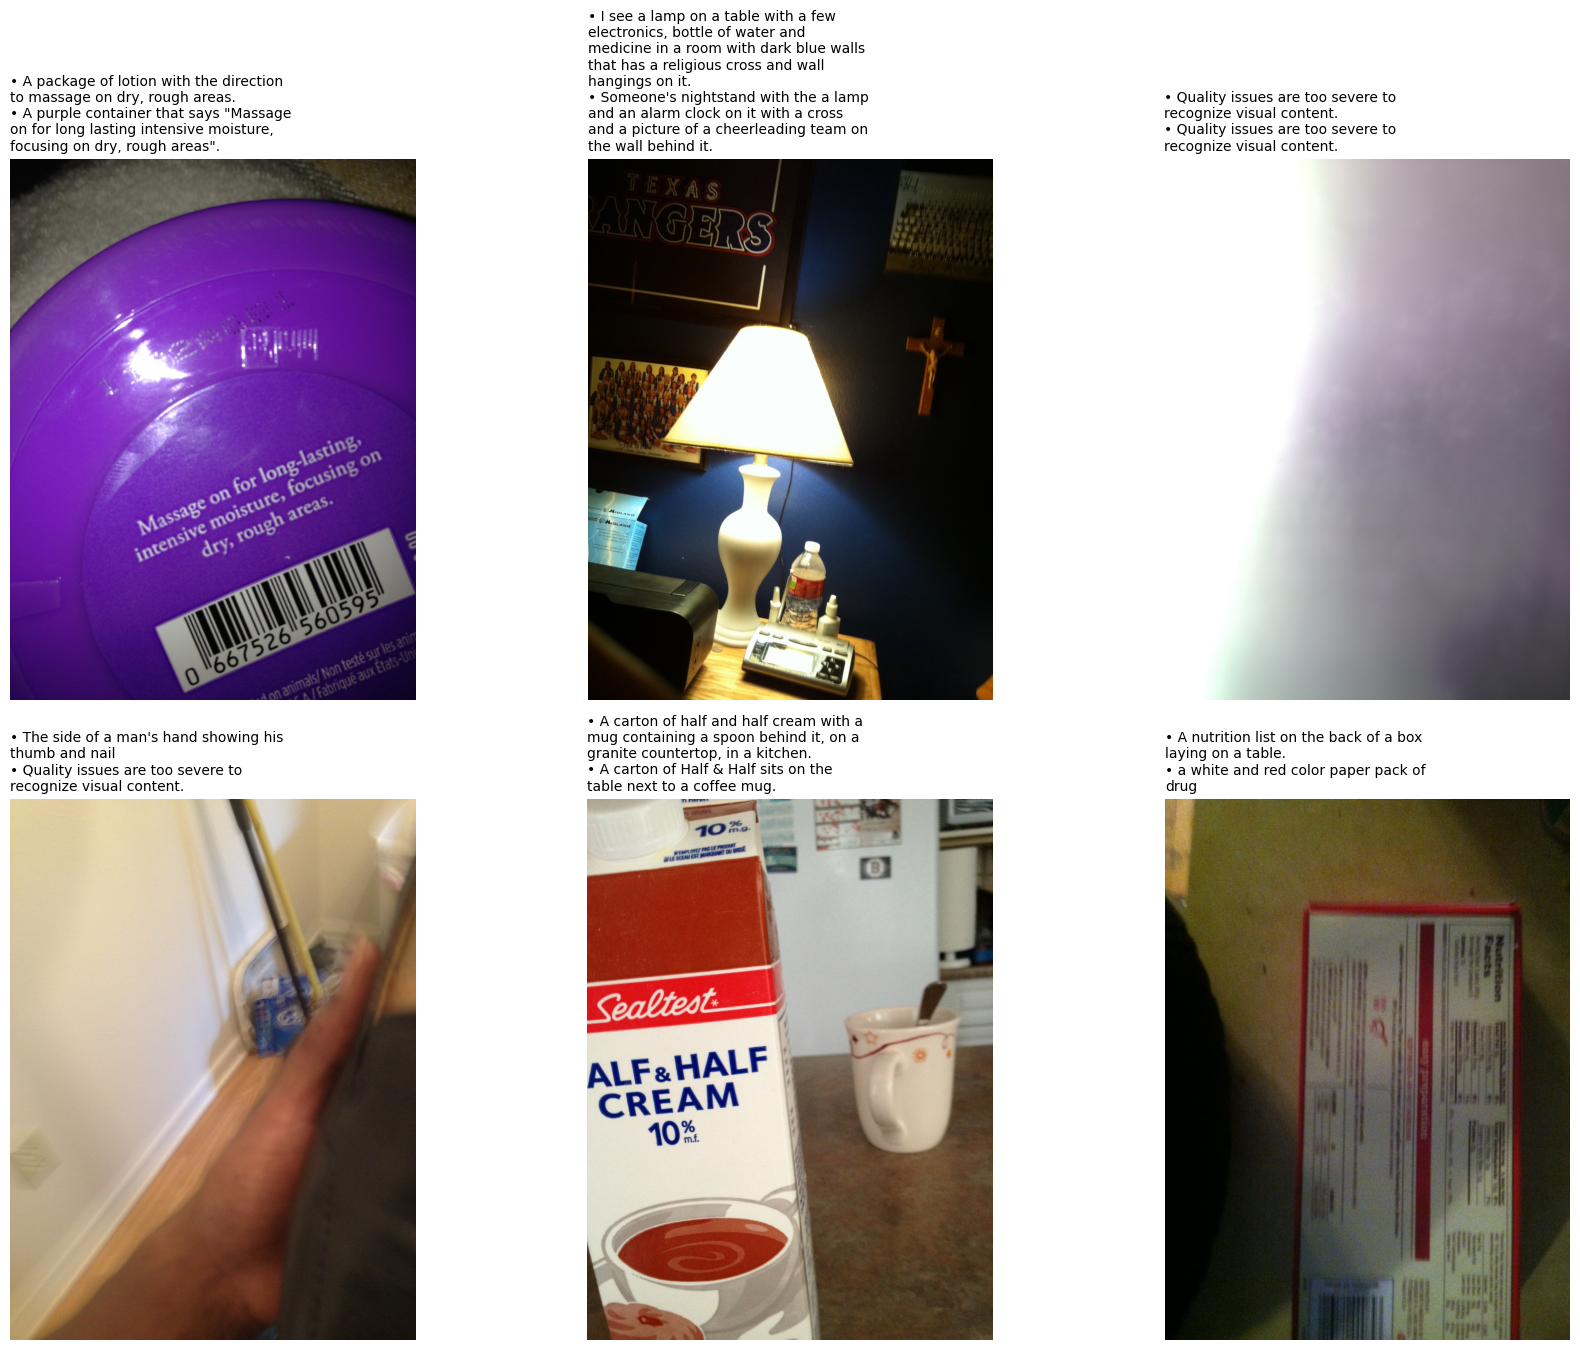

In [3]:
def find_file(file_name):
    # Ищет файл с таким именем внутри папки датасета
    return next(p for p in DATA_DIR.rglob(file_name) if p.is_file())


def load_split(split, image_paths):
    # Читает описания части датасета (train или val).
    # Возвращает список пар (путь к фото, список описаний); описания, отклонённые проверяющими, не берутся
    with open(find_file(f"{split}.json"), encoding="utf-8") as f:
        data = json.load(f)
    id_to_file = {img["id"]: img["file_name"] for img in data["images"]}

    captions = defaultdict(list)
    for ann in data["annotations"]:
        if ann.get("is_rejected", False):
            continue
        captions[ann["image_id"]].append(ann["caption"].strip())

    items = []
    missing = 0
    for image_id, caps in captions.items():
        path = image_paths.get(id_to_file[image_id])
        if path is None:
            missing += 1
        elif caps:
            items.append((path, caps))
    if missing:
        print(f"{split}: не найдено {missing} фото из описаний")
    return items


# Все фото датасета: имя файла -> путь
image_paths = {p.name: p for p in DATA_DIR.rglob("*.jpg")}

train_items = load_split("train", image_paths)
valid_items = load_split("val", image_paths)
print("Обучающих фото:", len(train_items), "описаний:", sum(len(c) for _, c in train_items))
print("Проверочных фото:", len(valid_items), "описаний:", sum(len(c) for _, c in valid_items))


def load_image(path):
    # Читает фото в RGB; draft уменьшает большое фото при чтении,
    # exif_transpose поворачивает фото так, как его снял телефон
    img = Image.open(path)
    img.draft("RGB", (768, 768))
    return ImageOps.exif_transpose(img).convert("RGB")


def show_with_captions(images, titles, cols=3, width=40):
    # Рисует фото в сетке, под каждым — его подпись с переносом длинных строк
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 6.8 * rows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, img, title in zip(np.ravel(axes), images, titles):
        ax.imshow(img)
        wrapped = "\n".join(textwrap.fill(line, width) for line in title.split("\n"))
        ax.set_title(wrapped, fontsize=10, loc="left")
    plt.tight_layout()
    plt.show()


# Несколько обучающих фото с двумя описаниями из пяти
examples = random.sample(train_items, 6)
show_with_captions(
    [load_image(p) for p, _ in examples],
    ["\n".join(f"• {c}" for c in caps[:2]) for _, caps in examples],
)

## 3. Инструменты оценки качества

In [4]:
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.rouge.rouge import Rouge

processor = BlipProcessor.from_pretrained(MODEL_NAME)


def load_base_model():
    # Загружает готовую BLIP без дообучения
    return BlipForConditionalGeneration.from_pretrained(MODEL_NAME).to(DEVICE)


@torch.no_grad()
def generate_captions(model, paths, batch=8, num_beams=NUM_BEAMS):
    # Пишет описание для каждого фото из списка; режим модели после вызова остаётся прежним
    was_training = model.training
    model.eval()
    captions = []
    for i in tqdm(range(0, len(paths), batch), desc="Описание фото", leave=False):
        images = [load_image(p) for p in paths[i:i + batch]]
        pixels = processor.image_processor(images=images, return_tensors="pt").pixel_values.to(DEVICE)
        ids = model.generate(pixel_values=pixels, num_beams=num_beams, max_new_tokens=MAX_LEN, min_length=5)
        captions.extend(processor.batch_decode(ids, skip_special_tokens=True))
    model.train(was_training)
    return [c.strip() for c in captions]


def normalize(text):
    # Приводит описание к виду для сравнения: маленькие буквы, без знаков препинания
    text = re.sub(r"[^a-z0-9 ]", " ", text.lower())
    return " ".join(text.split())


def caption_metrics(preds, refs):
    # Метрики описаний: preds — описания модели, refs — списки описаний людей для тех же фото.
    # BLEU — совпадение кусочков из 1 и 4 слов подряд, ROUGE-L — самая длинная общая цепочка слов,
    # CIDEr — совпадение с учётом того, насколько слово редкое и важное; для всех метрик больше — лучше
    gts = {i: [normalize(r) for r in rs] for i, rs in enumerate(refs)}
    res = {i: [normalize(p)] for i, p in enumerate(preds)}
    # Библиотека печатает служебные строки, они скрываются
    with redirect_stdout(io.StringIO()):
        bleu, _ = Bleu(4).compute_score(gts, res)
        rouge, _ = Rouge().compute_score(gts, res)
        cider, _ = Cider().compute_score(gts, res)
    return {"BLEU-1": float(bleu[0]), "BLEU-4": float(bleu[3]), "ROUGE-L": float(rouge), "CIDEr": float(cider)}


# Количество проверочных фото для итоговой оценки
EVAL_IMAGES = 1500
# Количество проверочных фото для быстрой оценки во время обучения
QUICK_IMAGES = 200

eval_items = random.Random(0).sample(valid_items, EVAL_IMAGES)
eval_paths = [p for p, _ in eval_items]
eval_refs = [caps for _, caps in eval_items]


def quick_cider(model):
    # CIDEr на первых QUICK_IMAGES фото из проверочной выборки; описания пишутся без перебора вариантов
    preds = generate_captions(model, eval_paths[:QUICK_IMAGES], num_beams=1)
    return caption_metrics(preds, eval_refs[:QUICK_IMAGES])["CIDEr"]

## 4. Оценка модели без дообучения

In [5]:
base_model = load_base_model()
base_preds = generate_captions(base_model, eval_paths)
base_results = caption_metrics(base_preds, eval_refs)
base_quick_cider = quick_cider(base_model)
# Освобождение памяти видеокарты
del base_model
torch.cuda.empty_cache()
print("BLIP без дообучения: " + ", ".join(f"{name} {value:.4f}" for name, value in base_results.items()))

Описание фото:   0%|          | 0/188 [00:00<?, ?it/s]

Описание фото:   0%|          | 0/25 [00:00<?, ?it/s]

BLIP без дообучения: BLEU-1 0.6148, BLEU-4 0.1980, ROUGE-L 0.4216, CIDEr 0.4702


## 5. Дообучение на VizWiz методом LoRA

In [6]:
class CaptionDataset(Dataset):
    # Пары «фото → описание» для обучения: каждую эпоху для фото берётся случайное из его описаний

    def __init__(self, items):
        # items — список пар (путь к фото, список описаний)
        self.items = items

    def __len__(self):
        # Количество фото за одну эпоху
        return len(self.items)

    def __getitem__(self, idx):
        # Фото, подготовленное для модели (384×384, нормированные цвета), и одно случайное описание
        path, caps = self.items[idx]
        pixels = processor.image_processor(images=load_image(path), return_tensors="pt").pixel_values[0]
        return pixels, random.choice(caps)


def collate(batch):
    # Собирает порцию: фото в один тензор, описания — в номера токенов одинаковой длины (короткие дополняются пустыми)
    pixels = torch.stack([b[0] for b in batch])
    tokens = processor.tokenizer(
        [b[1] for b in batch], padding="longest", truncation=True, max_length=MAX_LEN, return_tensors="pt"
    )
    return pixels, tokens.input_ids, tokens.attention_mask


def save_state(path, state):
    # Сохраняет состояние обучения через временный файл, прерванная запись не портит прошлое сохранение
    tmp_path = path.with_name(path.name + ".tmp")
    torch.save(state, tmp_path)
    os.replace(tmp_path, path)


# Количество эпох (проходов по всем обучающим фото)
EPOCHS = 2
# Количество фото в одной порции
BATCH_SIZE = 8
# Скорость обучения и ослабление весов для матриц LoRA
LR = 1e-4
WEIGHT_DECAY = 0.01
# Ранг LoRA (размер маленьких матриц) и множитель поправки
LORA_RANK = 16
LORA_ALPHA = 32

# Порции готовятся в основном процессе
train_loader = DataLoader(
    CaptionDataset(train_items),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=True,
    collate_fn=collate,
)

# Матрицы LoRA добавляются к слоям query, key и value самовнимания и внимания к картинке в текстовом декодере;
# все остальные веса BLIP заморожены
lora_config = LoraConfig(r=LORA_RANK, lora_alpha=LORA_ALPHA, lora_dropout=0.05, target_modules=["query", "key", "value"])
blip = load_base_model()
# Служебный токен, с которого BLIP начинает любое описание
BOS_ID = blip.config.text_config.bos_token_id
model = get_peft_model(blip, lora_config)

trainable = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(trainable, lr=LR, weight_decay=WEIGHT_DECAY)
total_steps = EPOCHS * len(train_loader)
# Первые 5% шагов скорость обучения плавно растёт, затем плавно снижается до нуля
scheduler = get_cosine_schedule_with_warmup(optimizer, int(0.05 * total_steps), total_steps)

# История обучения: ошибка на каждом шаге и CIDEr на быстрой проверке после каждой эпохи
step_losses = []
history_cider = [base_quick_cider]

state_path = CKPT_DIR / "blip_lora_state.pth"
start_epoch = 1

# Продолжение с места остановки, если есть сохранение
if state_path.exists():
    state = torch.load(state_path, map_location="cpu")
    set_peft_model_state_dict(model, state["lora"])
    optimizer.load_state_dict(state["optimizer"])
    scheduler.load_state_dict(state["scheduler"])
    step_losses, history_cider = state["step_losses"], state["history_cider"]
    start_epoch = state["epoch"] + 1
    print(f"Найдено сохранение {state_path.name}: пройдено эпох {state['epoch']} из {EPOCHS}")
    del state

model.train()
for epoch in range(start_epoch, EPOCHS + 1):
    start = time.time()
    # Ошибки текущей эпохи; в общую историю попадают только после её окончания
    epoch_losses = []
    for pixels, input_ids, attention_mask in tqdm(train_loader, desc=f"Эпоха {epoch}/{EPOCHS}", leave=False):
        pixels = pixels.to(DEVICE, non_blocking=True)
        input_ids = input_ids.to(DEVICE, non_blocking=True)
        attention_mask = attention_mask.to(DEVICE, non_blocking=True)

        # Описание начинается со служебного токена, как при генерации; пустые позиции не учитываются в ошибке (-100)
        input_ids[:, 0] = BOS_ID
        labels = input_ids.masked_fill(attention_mask == 0, -100)

        loss = model(pixel_values=pixels, input_ids=input_ids, attention_mask=attention_mask, labels=labels).loss

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        # Ограничение размера шага обучения
        torch.nn.utils.clip_grad_norm_(trainable, 1.0)
        optimizer.step()
        scheduler.step()
        epoch_losses.append(loss.item())

    step_losses.extend(epoch_losses)
    cider = quick_cider(model)
    history_cider.append(cider)

    # Сохранение всего состояния обучения после каждой эпохи
    save_state(state_path, {
        "epoch": epoch,
        "step_losses": step_losses,
        "history_cider": history_cider,
        "lora": get_peft_model_state_dict(model),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
    })
    print(f"Эпоха {epoch}: ошибка {np.mean(epoch_losses):.4f}, CIDEr на быстрой проверке {cider:.4f}, "
          f"{time.time() - start:.0f} с")

Эпоха 1/2:   0%|          | 0/2928 [00:00<?, ?it/s]

Описание фото:   0%|          | 0/25 [00:00<?, ?it/s]

Эпоха 1: ошибка 3.0668, CIDEr на быстрой проверке 1.1238, 10490 с


Эпоха 2/2:   0%|          | 0/2928 [00:00<?, ?it/s]

Описание фото:   0%|          | 0/25 [00:00<?, ?it/s]

Эпоха 2: ошибка 2.8634, CIDEr на быстрой проверке 0.8069, 9641 с


## 6. Оценка на проверочных фото

In [7]:
tuned_preds = generate_captions(model, eval_paths)
tuned_results = caption_metrics(tuned_preds, eval_refs)
results = {"BLIP без дообучения": base_results, "BLIP + VizWiz (LoRA)": tuned_results}

# Итоговая таблица: для всех метрик больше — лучше
print(f"Проверочных фото: {len(eval_paths)}")
print(f"{'Модель':<22}{'BLEU-1':>9}{'BLEU-4':>9}{'ROUGE-L':>9}{'CIDEr':>9}")
for name, m in results.items():
    print(f"{name:<22}{m['BLEU-1']:>9.4f}{m['BLEU-4']:>9.4f}{m['ROUGE-L']:>9.4f}{m['CIDEr']:>9.4f}")

# Средняя длина описаний в словах: у людей и у моделей
print(f"\nСредняя длина описания, слов: люди {np.mean([len(c.split()) for r in eval_refs for c in r]):.1f}, "
      f"без дообучения {np.mean([len(c.split()) for c in base_preds]):.1f}, "
      f"с дообучением {np.mean([len(c.split()) for c in tuned_preds]):.1f}")

# В VizWiz люди пишут готовую фразу «Quality issues are too severe…» для фото, на которых ничего не разобрать
QUALITY_PHRASE = "quality issues"
print(f"Доля фото, где хотя бы один человек написал «{QUALITY_PHRASE}…»: "
      f"{np.mean([any(QUALITY_PHRASE in c.lower() for c in r) for r in eval_refs]):.1%}")
print(f"Доля таких описаний среди всех описаний людей: "
      f"{np.mean([QUALITY_PHRASE in c.lower() for r in eval_refs for c in r]):.1%}")
print(f"Доля таких ответов у модели с дообучением: {np.mean([QUALITY_PHRASE in c.lower() for c in tuned_preds]):.1%}")

Описание фото:   0%|          | 0/188 [00:00<?, ?it/s]

Проверочных фото: 1500
Модель                   BLEU-1   BLEU-4  ROUGE-L    CIDEr
BLIP без дообучения      0.6148   0.1980   0.4216   0.4702
BLIP + VizWiz (LoRA)     0.6136   0.3364   0.5435   1.4129

Средняя длина описания, слов: люди 11.8, без дообучения 9.9, с дообучением 12.7
Доля фото, где хотя бы один человек написал «quality issues…»: 28.7%
Доля таких описаний среди всех описаний людей: 12.5%
Доля таких ответов у модели с дообучением: 34.6%


## 7. Визуальное сравнение

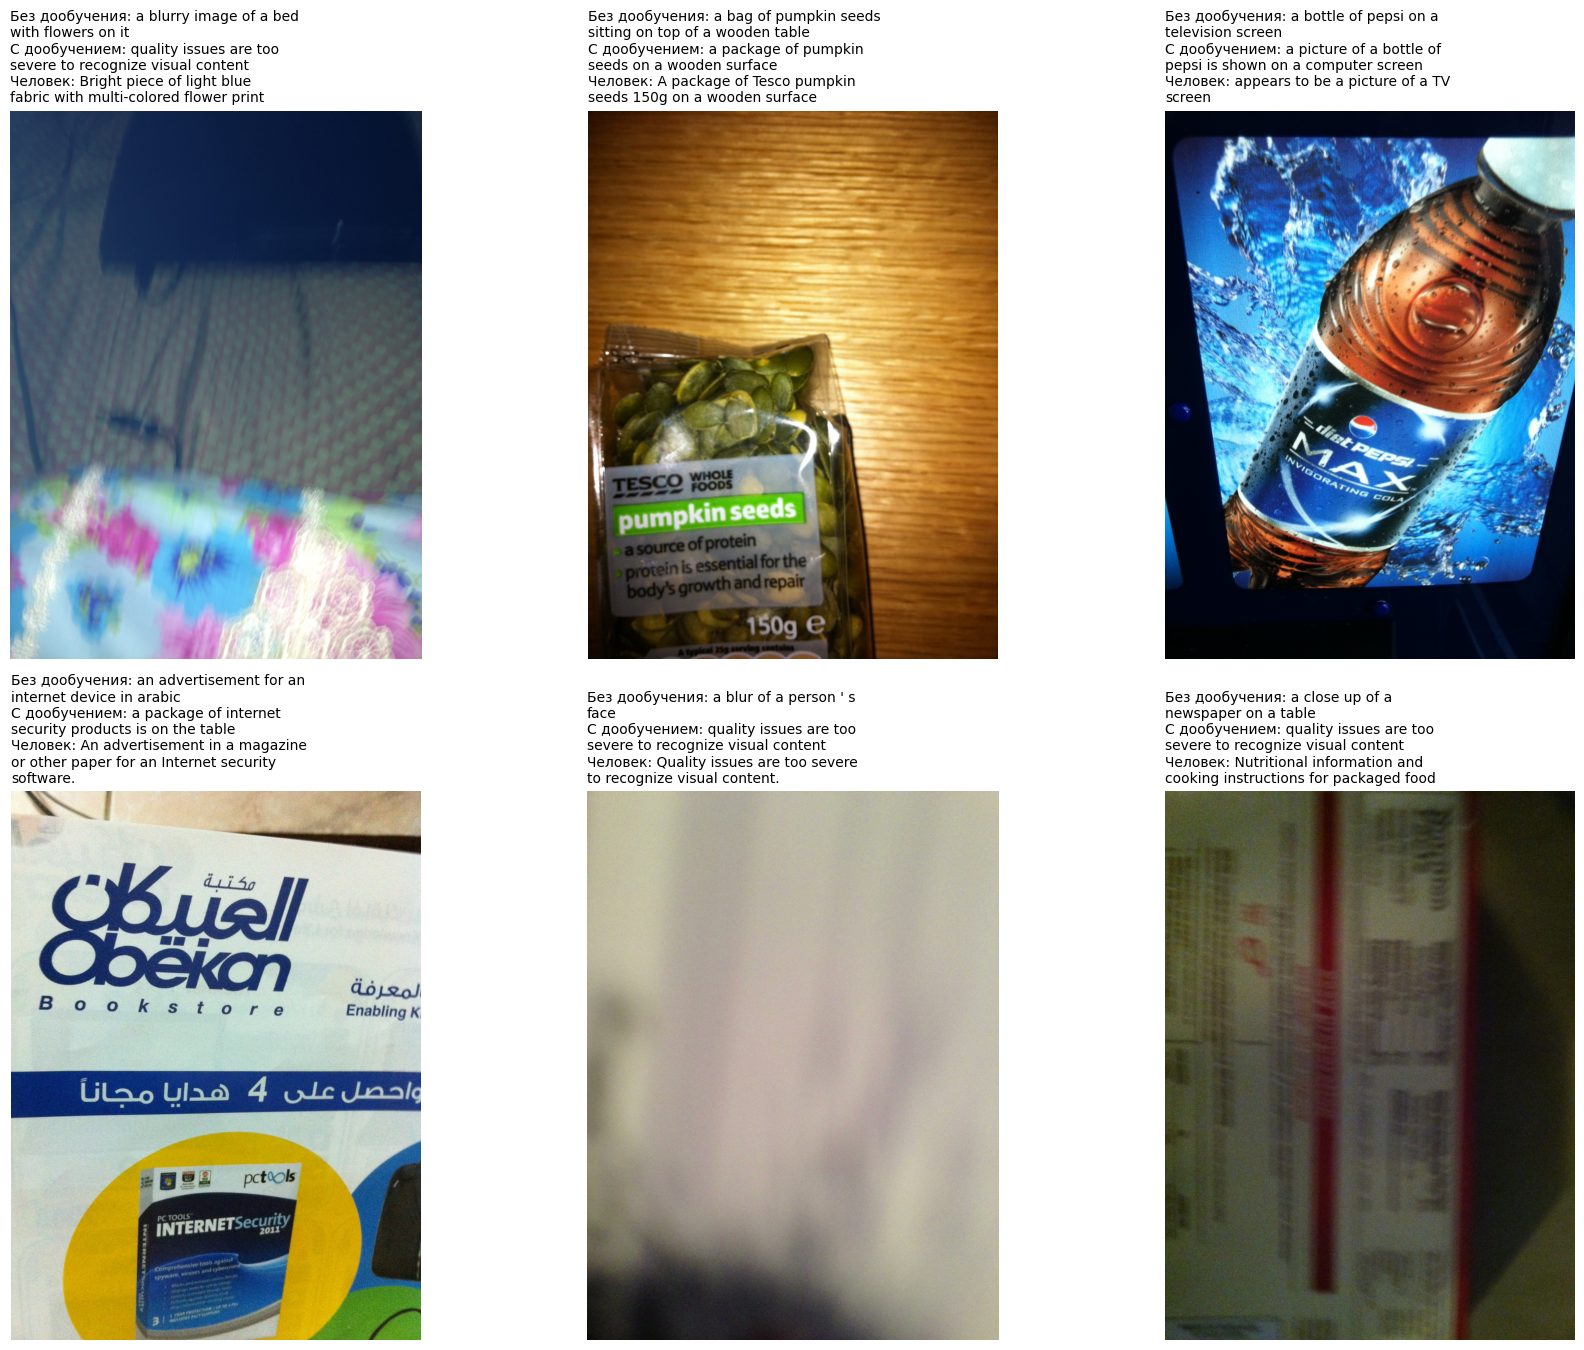

In [8]:
# Номера проверочных фото для показа
SHOW_IDS = [0, 100, 200, 300, 400, 500]

show_with_captions(
    [load_image(eval_paths[i]) for i in SHOW_IDS],
    [f"Без дообучения: {base_preds[i]}\nС дообучением: {tuned_preds[i]}\nЧеловек: {eval_refs[i][0]}" for i in SHOW_IDS],
)

## 8. Графики обучения

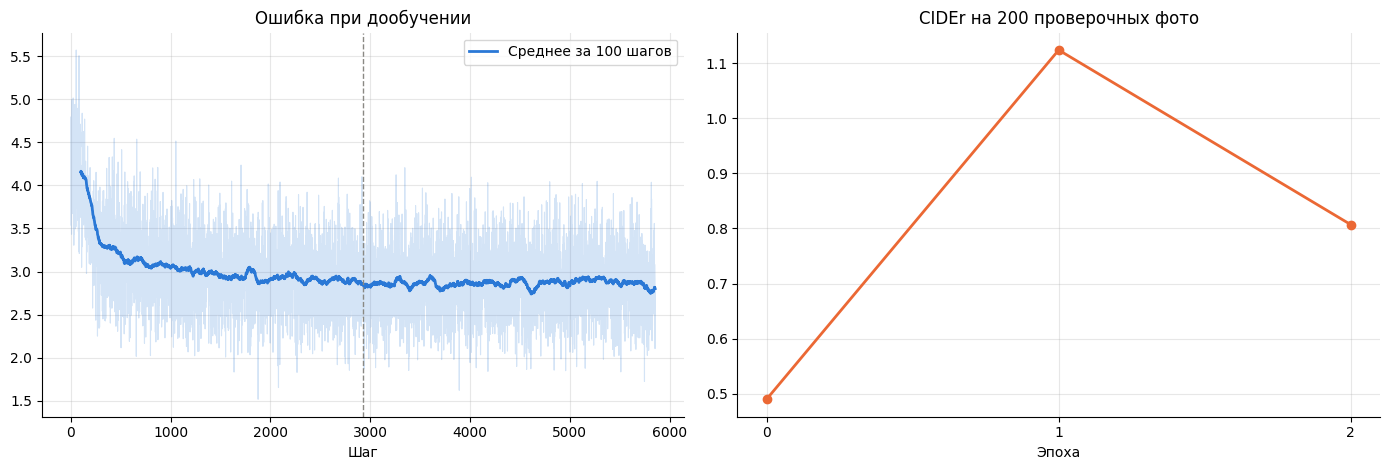

In [9]:
# Цвета линий: синий — ошибка обучения, оранжевый — CIDEr
COLOR_LOSS, COLOR_CIDER = "#2a78d6", "#eb6834"
# Количество шагов для сглаживания ошибки: значения на отдельных шагах сильно скачут
SMOOTH = 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Ошибка на каждом шаге и её скользящее среднее
ax = axes[0]
steps = np.arange(1, len(step_losses) + 1)
smooth = np.convolve(step_losses, np.ones(SMOOTH) / SMOOTH, mode="valid")
ax.plot(steps, step_losses, color=COLOR_LOSS, alpha=0.2, lw=0.8)
ax.plot(steps[SMOOTH - 1:], smooth, color=COLOR_LOSS, lw=2, label=f"Среднее за {SMOOTH} шагов")
# Вертикальные линии — границы эпох
for e in range(1, EPOCHS):
    ax.axvline(e * len(train_loader), color="#8a8984", ls="--", lw=1)
ax.set_title("Ошибка при дообучении")
ax.set_xlabel("Шаг")
ax.legend()

# CIDEr на быстрой проверке: эпоха 0 — модель без дообучения
ax = axes[1]
ax.plot(range(len(history_cider)), history_cider, color=COLOR_CIDER, lw=2, marker="o", ms=6)
ax.set_title(f"CIDEr на {QUICK_IMAGES} проверочных фото")
ax.set_xlabel("Эпоха")
ax.set_xticks(range(len(history_cider)))

# Светлая сетка
for ax in axes:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

## 9. Демонстрация на своих фото

Фото (.png / .bmp / .jpg) для демонстрации кладутся в папку `images` рядом с ноутбуком. Для каждого фото показываются описания обеих моделей.

Описание фото:   0%|          | 0/1 [00:00<?, ?it/s]

Описание фото:   0%|          | 0/1 [00:00<?, ?it/s]

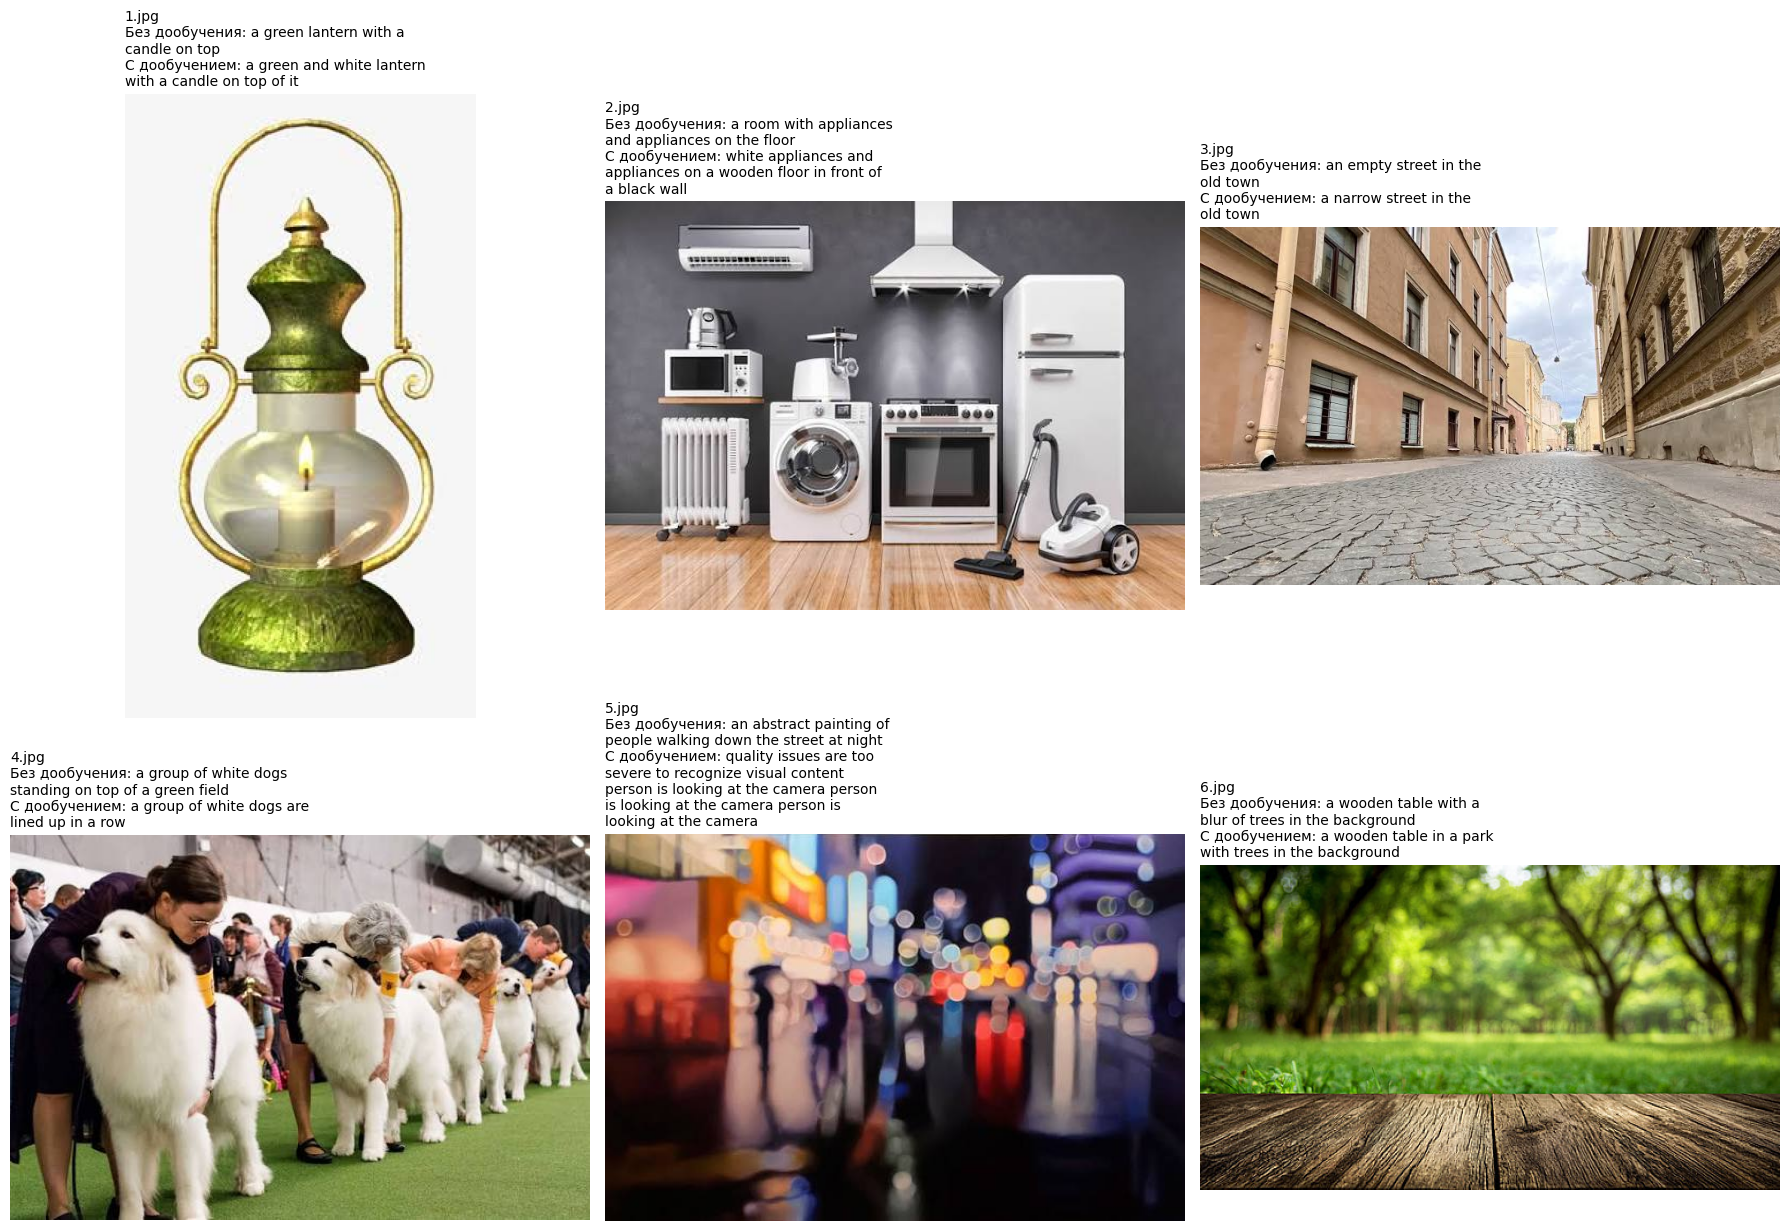

In [11]:
# Расширения файлов, которые считаются фото
IMAGE_TYPES = {".png", ".bmp", ".jpg", ".jpeg"}
paths = sorted(p for p in IMAGES_DIR.iterdir() if p.suffix.lower() in IMAGE_TYPES)
if not paths:
    raise FileNotFoundError(f"В папке {IMAGES_DIR} нет фото .png, .bmp или .jpg")

tuned_caps = generate_captions(model, paths)

# Модель без дообучения загружается только на время описания
base_model = load_base_model()
base_caps = generate_captions(base_model, paths)
del base_model
torch.cuda.empty_cache()

show_with_captions(
    [load_image(p) for p in paths],
    [f"{p.name}\nБез дообучения: {b}\nС дообучением: {t}" for p, b, t in zip(paths, base_caps, tuned_caps)],
    cols=min(3, len(paths)),
)

## Выводы

1. **Решена задача** генерации текстового описания к изображению. За основу взята готовая модель BLIP (`blip-image-captioning-base`), дообученная на датасете VizWiz-Captions (23 431 обучающее фото, по 5 описаний к каждому). Применено дообучение методом LoRA: обучались только добавочные матрицы в слоях внимания текстового декодера, около 1,8 млн параметров (меньше 1% модели).

2. **Результаты на 1500 проверочных фото:**

   | Модель | BLEU-1 | BLEU-4 | ROUGE-L | CIDEr |
   |---|---|---|---|---|
   | BLIP без дообучения | 0.6148 | 0.1980 | 0.4216 | 0.4702 |
   | BLIP + VizWiz (LoRA) | 0.6136 | **0.3364** | **0.5435** | **1.4129** |

3. **Дообучение значительно улучшило описания:** CIDEr вырос в 3 раза (0,47 → 1,41), BLEU-4 — в 1,7 раза, ROUGE-L — на 0,12. BLEU-1 почти не изменился: отдельные слова модель угадывала и без дообучения, а выросло совпадение целых фраз и порядка слов. Модель усвоила манеру описаний VizWiz: называет конкретный предмет и его содержимое («a package of pumpkin seeds on a wooden surface»), а не общую сцену. Средняя длина описания приблизилась к человеческой (12,7 слова против 11,8 у людей и 9,9 у модели без дообучения).

4. **Модель научилась распознавать неразборчивые снимки, но злоупотребляет этим.** Для неразборчивых снимков люди пишут стандартную фразу «Quality issues are too severe to recognize visual content»: она встречается в 12,5% всех описаний, и хотя бы один из пяти человек написал её для 28,7% фото. Модель без дообучения на таких снимках выдумывает содержимое («a blur of a person's face»), а дообученная отвечает этой фразой. Однако она выдаёт её для 34,6% фото — почти в 3 раза чаще, чем люди (12,5%), и даже чаще, чем доля фото, где так ответил хотя бы один человек. То есть модель нередко отказывается описывать снимок, на котором люди различают предмет.

5. **По графикам обучения:** ошибка быстро падает в первые ~500 шагов и дальше снижается медленно. CIDEr на быстрой проверке (200 фото) вырос с 0,49 до 1,12 после первой эпохи и упал до 0,81 после второй. Эта проверка шумная, но падение согласуется с перекосом в сторону фразы «quality issues»: вероятно, одной эпохи было бы достаточно, а вторая усилила перекос.

6. **На собственных фото** дообученная модель описывает предметы так же хорошо или подробнее («a green and white lantern with a candle on top of it»), но переносит на обычные фото манеру VizWiz: на размытом художественном снимке ночного города она выдала «quality issues…» и затем зациклилась на повторе фразы. Повторы можно устранить запретом на повтор слов при генерации (параметр `no_repeat_ngram_size`).

7. **Применение LoRA оправдано:** обучение 1% параметров дало кратный прирост качества на новом типе данных при небольших затратах памяти и времени.